# 호텔 예약 취소 예측: 데이터 확인
1. 범주형을 정수로 바꿔 상관계수 보기
2. 이상치 확인하기
3. 이상치 제거

### 0. 준비
아래 셀을 실행하면 파일 선택 창이 뜹니다. `hotel_bookings.csv`를 올려주세요.
(구글 드라이브에 있다면 두 번째 셀의 주석을 풀고 경로를 바꿔 쓰세요.)

In [52]:
!pip install -q koreanize-matplotlib

In [53]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import koreanize_matplotlib
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix
from sklearn.tree import plot_tree
from scipy.stats import uniform, randint
from sklearn.model_selection import RandomizedSearchCV

In [54]:
from google.colab import drive
drive.mount('/content/drive')

url = "/content/drive/MyDrive/Colab Notebooks/bigdata/"
df = pd.read_csv(url+"hotel_bookings.csv")

df.sample(10)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,hotel,lead_time,arrival_month,adults,children,babies,country,market_segment,deposit_type,customer_type,adr,previous_cancellations,special_requests,is_canceled
369,Resort Hotel,27,Jun,2,1.0,0,JPN,Online,Refundable,Transient,91.0,1,0,0
54,Resort Hotel,298,Mar,4,0.0,0,FRA,Agent,Non Refund,Contract,140.0,5,0,1
334,City Hotel,316,Nov,4,0.0,0,KOR,Agent,Refundable,Transient,145.0,4,4,1
185,Resort Hotel,177,Aug,3,0.0,0,CHN,Offline,Refundable,Group,120.0,0,1,1
114,Resort Hotel,318,Jul,1,0.0,0,KOR,Offline,Non Refund,Group,113.0,4,0,1
309,City Hotel,201,May,2,0.0,0,GBR,Online,No Deposit,Group,62.0,0,4,1
156,Resort Hotel,340,Jun,1,1.0,0,CHN,Corporate,No Deposit,Transient,56.0,1,2,1
397,City Hotel,238,Sep,2,0.0,0,FRA,Online,Non Refund,Group,293.0,1,4,1
48,City Hotel,341,Sep,2,0.0,0,GBR,Online,Refundable,Contract,225.0,1,0,0
250,City Hotel,205,Sep,2,0.0,1,USA,Online,Refundable,Contract,197.0,3,0,1


In [55]:
df['is_canceled'] = df['is_canceled'].map({'0': 0, '1': 1})

In [56]:
df.info()   # 자료형과 결측치 확인

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 457 entries, 0 to 456
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   hotel                   457 non-null    object 
 1   lead_time               457 non-null    int64  
 2   arrival_month           457 non-null    object 
 3   adults                  457 non-null    int64  
 4   children                449 non-null    float64
 5   babies                  457 non-null    int64  
 6   country                 450 non-null    object 
 7   market_segment          457 non-null    object 
 8   deposit_type            453 non-null    object 
 9   customer_type           457 non-null    object 
 10  adr                     452 non-null    float64
 11  previous_cancellations  457 non-null    int64  
 12  special_requests        457 non-null    int64  
 13  is_canceled             0 non-null      float64
dtypes: float64(3), int64(5), object(6)
memory 

## 1. 범주형을 정수로 바꿔 상관계수 보기
- 월은 순서가 있으니 직접 1~12로 바꿉니다.
- 나머지 범주형은 알파벳 순서대로 0, 1, 2 … 번호가 붙습니다. 빈 칸은 -1이 됩니다.

In [57]:
data = df.copy()          # 원본은 그대로 두고 복사본으로 작업

# 1) 월은 순서가 있으니 직접 숫자로
month = {'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5, 'Jun': 6,
         'Jul': 7, 'Aug': 8, 'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12}
data['arrival_month'] = data['arrival_month'].map(month)

# 2) 나머지 범주형은 0, 1, 2 ... 로 자동 변환
cat_cols = ['hotel', 'country', 'market_segment', 'deposit_type', 'customer_type']
for col in cat_cols:
    data[col] = data[col].astype('category')
    print(col, dict(enumerate(data[col].cat.categories)))   # 어떤 숫자가 무슨 값인지
    data[col] = data[col].cat.codes

data.head()

hotel {0: 'City Hotel', 1: 'Resort Hotel'}
country {0: 'CHN', 1: 'FRA', 2: 'GBR', 3: 'JPN', 4: 'KOR', 5: 'USA'}
market_segment {0: 'Agent', 1: 'Corporate', 2: 'Offline', 3: 'Online'}
deposit_type {0: 'No Deposit', 1: 'Non Refund', 2: 'Refundable'}
customer_type {0: 'Contract', 1: 'Group', 2: 'Transient'}


,hotel,lead_time,arrival_month,adults,children,babies,country,market_segment,deposit_type,customer_type,adr,previous_cancellations,special_requests,is_canceled
0,1,263,12,2,0.0,0,4,3,2,2,227.0,0,1,NaN
1,0,282,2,2,0.0,0,2,0,0,0,328.0,1,2,NaN
2,1,26,6,2,1.0,0,1,1,2,1,195.0,5,2,NaN
3,1,225,2,2,0.0,0,1,2,0,1,1500.0,2,4,NaN
4,1,276,2,2,2.0,0,4,1,0,1,111.0,1,2,NaN


In [58]:
# 3) 취소여부(is_canceled)와의 상관계수만 정렬
corr = data.corr()
corr['is_canceled'].sort_values(ascending=False).round(2)

,is_canceled
hotel,NaN
lead_time,NaN
arrival_month,NaN
adults,NaN
children,NaN
babies,NaN
country,NaN
market_segment,NaN
deposit_type,NaN
customer_type,NaN


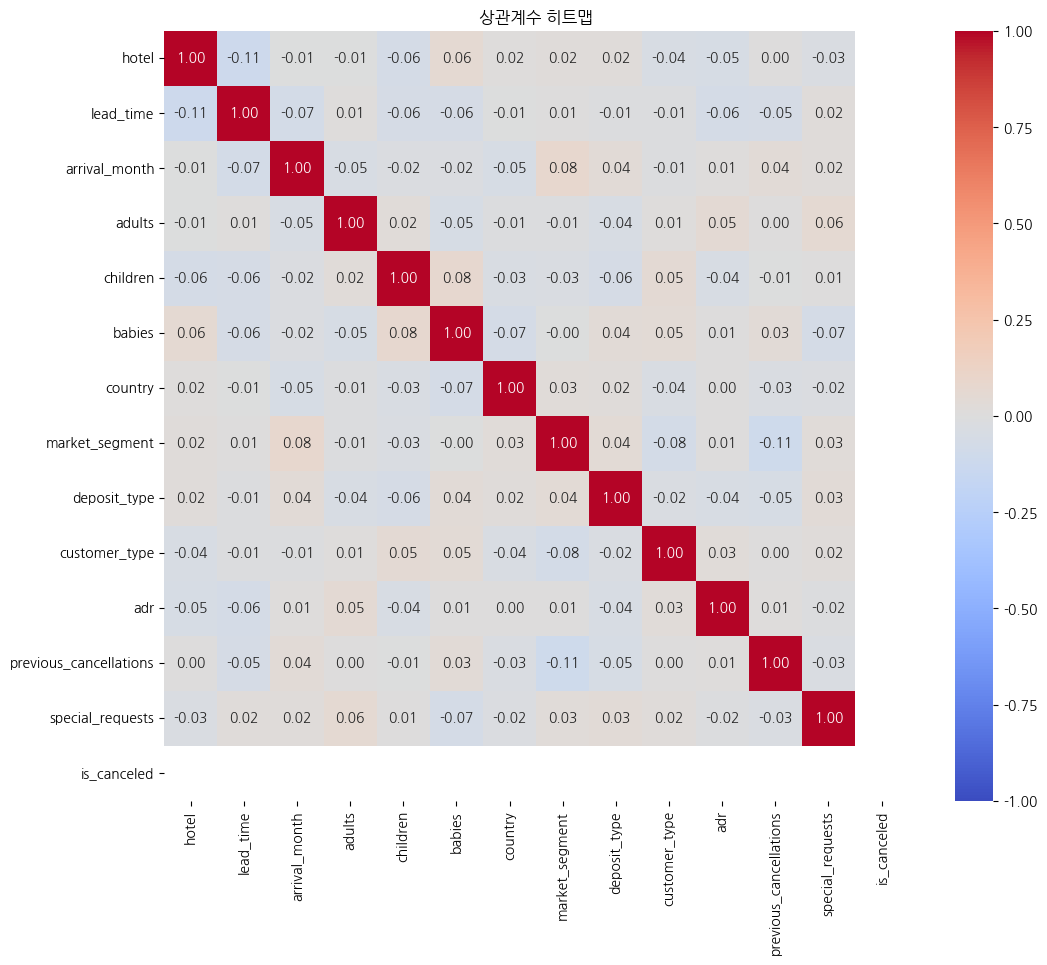

In [59]:
# 4) 히트맵
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('상관계수 히트맵')
plt.show()

**해석 시 주의**
- 정수 번호에는 크기 의미가 없어서 관계가 왜곡될 수 있습니다.
  - 예: customer_type은 0.05로 나오지만 실제로는 Group의 취소율이 94%입니다.
- 그래서 이 결과는 훑어보기용으로만 쓰세요.
- 모델에 넣을 때는 이렇게 하면 됩니다.
  - 트리 모델(결정트리, 랜덤포레스트): 정수 그대로 사용
  - 로지스틱 회귀, KNN: `pd.get_dummies` 원-핫 인코딩

## 2. 이상치 확인하기

In [60]:
num_cols = ['lead_time', 'adults', 'children', 'babies', 'adr',
            'previous_cancellations', 'special_requests']

# 1) 요약 통계: min, max가 상식적인지 확인
df[num_cols].describe()

,lead_time,adults,children,babies,adr,previous_cancellations,special_requests
count,457.000000,457.000000,449.000000,457.000000,452.000000,457.000000,457.000000
mean,181.516411,2.317287,0.389755,0.045952,229.280973,2.595186,2.048140
std,131.235593,1.364488,0.669476,0.209610,270.274359,1.679409,1.385182
min,0.000000,1.000000,0.000000,0.000000,-50.000000,0.000000,0.000000
25%,95.000000,2.000000,0.000000,0.000000,143.000000,1.000000,1.000000
50%,176.000000,2.000000,0.000000,0.000000,225.000000,3.000000,2.000000
75%,258.000000,3.000000,1.000000,0.000000,281.250000,4.000000,3.000000
max,1500.000000,20.000000,2.000000,1.000000,5000.000000,5.000000,4.000000


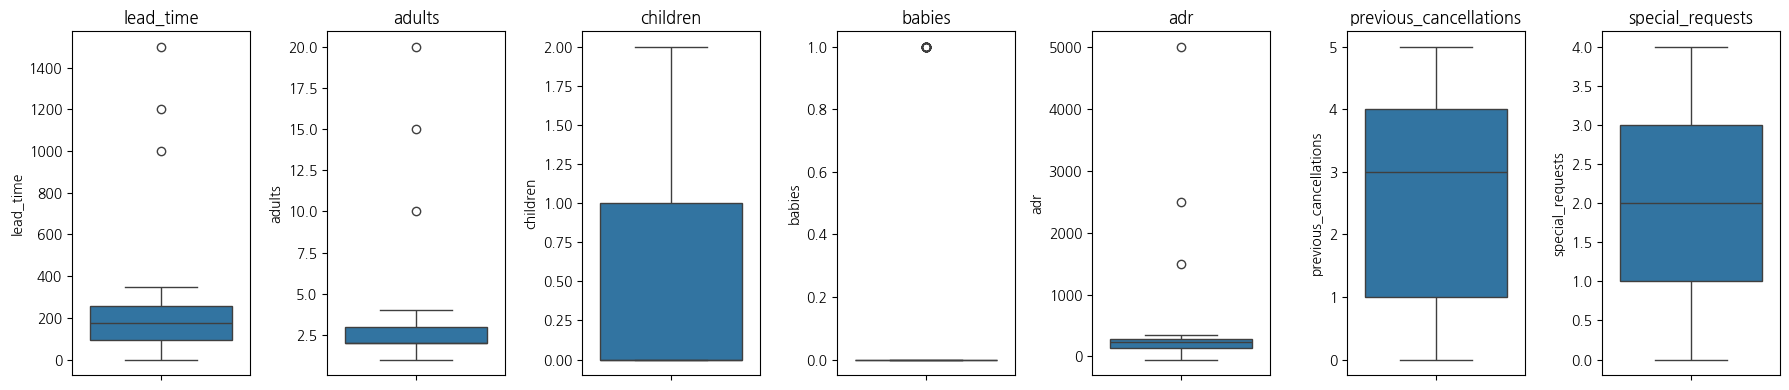

In [61]:
# 2) 박스플롯: 상자 밖으로 튀어나온 점이 이상치 후보
fig, axes = plt.subplots(1, 7, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [62]:
# 3) IQR 방법으로 이상치 개수와 값 출력
for col in num_cols:
    Q1 = df[col].quantile(0.25)          # 하위 25%
    Q3 = df[col].quantile(0.75)          # 상위 25%
    IQR = Q3 - Q1
    low, high = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    out = df[(df[col] < low) | (df[col] > high)][col]
    print(f'{col}: 정상범위 {low:.0f} ~ {high:.0f}, 이상치 {len(out)}개 → {sorted(out.tolist())}')

lead_time: 정상범위 -150 ~ 502, 이상치 3개 → [999, 1200, 1500]
adults: 정상범위 0 ~ 4, 이상치 3개 → [10, 15, 20]
children: 정상범위 -2 ~ 2, 이상치 0개 → []
babies: 정상범위 0 ~ 0, 이상치 21개 → [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
adr: 정상범위 -64 ~ 489, 이상치 3개 → [1500.0, 2500.0, 5000.0]
previous_cancellations: 정상범위 -4 ~ 8, 이상치 0개 → []
special_requests: 정상범위 -2 ~ 6, 이상치 0개 → []


**IQR 결과를 그대로 믿으면 안 되는 경우**
- babies 21개는 정상 값입니다. 대부분이 0이라서 아기 1명인 예약까지 이상치로 잡힌 겁니다.
- adr = -50(음수 요금)은 IQR 정상범위 안이라 못 잡습니다. 상식으로 따로 걸러야 합니다.

## 3. 이상치 제거

In [63]:
"""print('제거 전:', len(df))
df_clean = df[(df['lead_time'] <= 365) &
              (df['adults'] <= 6) &
              (df['adr'].between(0, 1000) | df['adr'].isna())]
print('제거 후:', len(df_clean))

_IncompleteInputError: incomplete input (2799834333.py, line 1)

In [72]:
X = data.drop(columns=["previous_cancellations", "lead_time", "hotel", "deposit_type", "arrival_month"])
y = data["is_canceled"]

X = X.fillna(0)

In [73]:
# 결측치와 이상치가 정상적으로 제거된 df_clean 데이터프레임을 기반으로 X, y를 다시 정의합니다.
# 범주형 변수를 모델이 처리할 수 있도록 원-핫 인코딩(One-Hot Encoding)을 적용합니다.
df_features = df_clean.drop(columns=['is_canceled', 'previous_cancellations', 'lead_time', 'hotel', 'deposit_type', 'arrival_month'])
X_encoded = pd.get_dummies(df_features, drop_first=True)
y_clean = df_clean['is_canceled'].astype(int)

# 이제 NaN이 없는 안전한 데이터를 사용하여 Train/Test 분할을 진행합니다.
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y_clean, test_size=0.3, random_state=42, stratify=y_clean)

print("학습 데이터 형태:", X_train.shape)
print("테스트 데이터 형태:", X_test.shape)

학습 데이터 형태: (312, 15)
테스트 데이터 형태: (135, 15)


In [74]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [90]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

# 원본 데이터프레임(df)의 텍스트 컬럼들을 숫자로 원-핫 인코딩하여 학습을 진행합니다.
X_train_en = pd.get_dummies(X_train)
X_test_en = pd.get_dummies(X_test)

# train과 test의 인코딩 후 컬럼 순서 및 개수를 맞춰줍니다.
X_train_en, X_test_en = X_train_en.align(X_test_en, join='left', axis=1, fill_value=0)

# 결정 트리 모델 생성 및 학습
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train_en, y_train)

# 결과 출력
print("학습 정확도:", dt.score(X_train_en, y_train))
print("테스트 정확도:", dt.score(X_test_en, y_test))

학습 정확도: 0.7756410256410257
테스트 정확도: 0.6962962962962963


In [98]:
print(dt.score(X_train_en,y_train))

0.7756410256410257


In [99]:
print(dt.score(X_test_en,y_test))

0.6962962962962963


In [86]:
pr = dt.predict(X_test_en)
cm = confusion_matrix(y_test, pr)
print(cm)

[[14 32]
 [ 9 80]]


In [91]:
pr_train = dt.predict(X_train_en)
cm = confusion_matrix(y_train, pr_train)
print(cm)

[[ 43  63]
 [  7 199]]


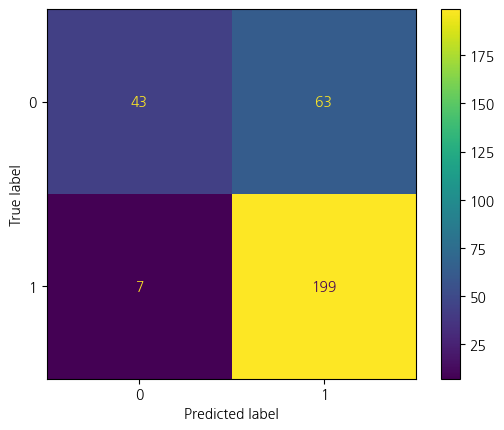

In [96]:
ConfusionMatrixDisplay.from_predictions(y_train, pr_train)
plt.show()

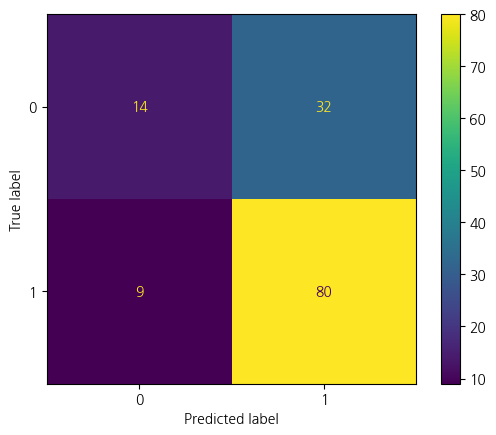

In [97]:
ConfusionMatrixDisplay.from_predictions(y_test, pr)
plt.show()

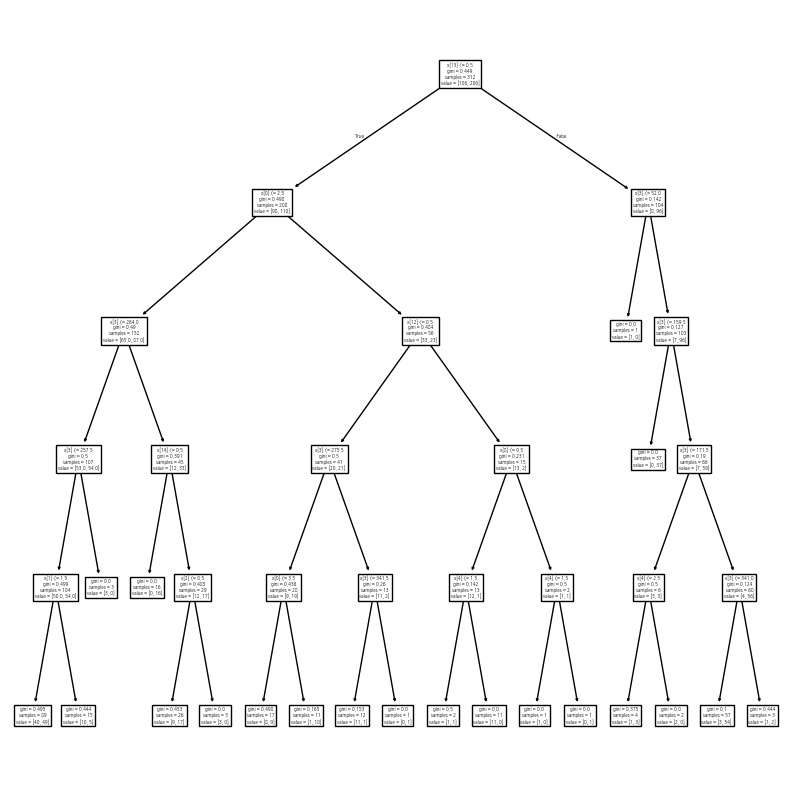

In [100]:
plt.figure(figsize=(10,10))
plot_tree(dt,max_depth=5)
plt.show()

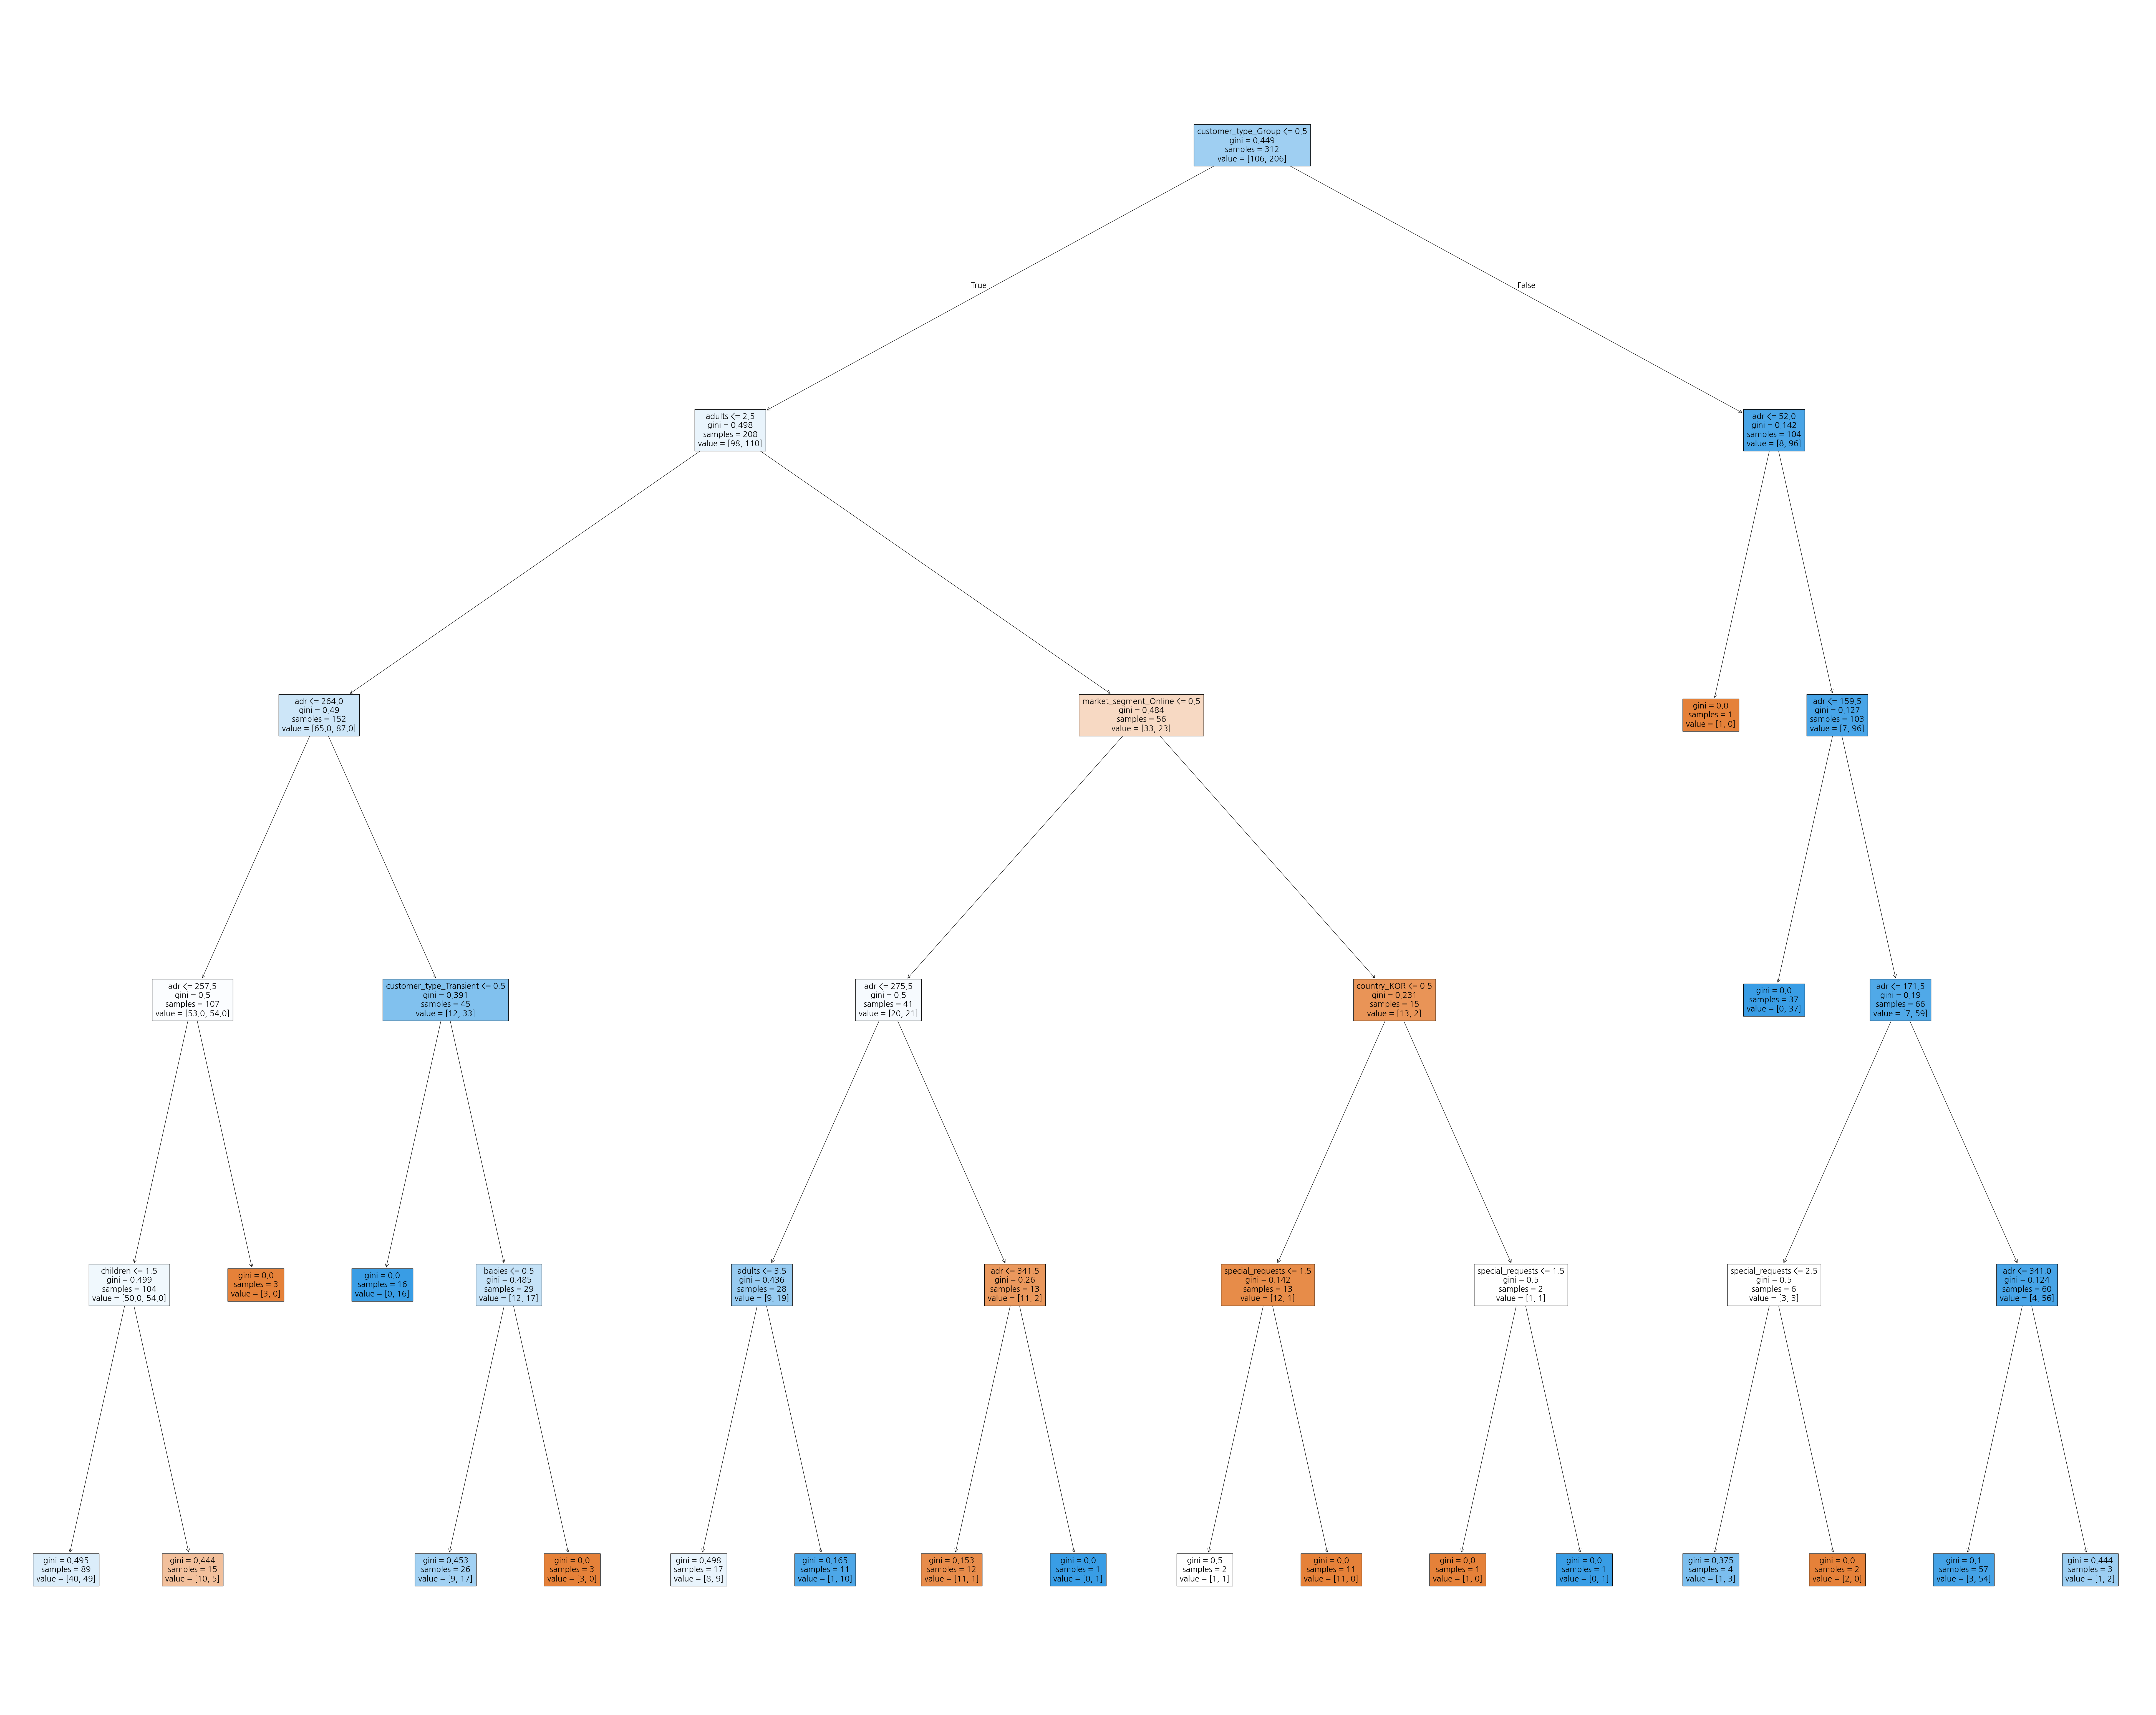

In [103]:
plt.figure(figsize=(100,80))
plot_tree(
    dt, max_depth=5,
    filled=True,
    feature_names=list(X_train_en.columns)
)
plt.show()

In [102]:
print(dt.feature_importances_)

[0.0727671  0.02168993 0.04117413 0.28783485 0.05990908 0.
 0.         0.         0.01110958 0.         0.         0.
 0.05644499 0.38585118 0.06321915]


#**교차검증**

In [120]:
sub_input, val_input, sub_target, val_target = train_test_split(
    X_train_en, y_train, test_size=0.3, random_state=42)
print(sub_input.shape, val_input.shape, sub_target.shape, val_target.shape)

(218, 15) (94, 15) (218,) (94,)


In [121]:
cross=DecisionTreeClassifier(max_depth=5,random_state=42)
cross.fit(sub_input,sub_target)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [122]:
print(dt.score(sub_input,sub_target))

0.7844036697247706


In [123]:
print(dt.score(val_input,val_target))

0.7553191489361702


In [124]:
from sklearn.model_selection import cross_validate

scs =cross_validate(cross,X_train_en,y_train)
print(scs)

{'fit_time': array([0.00457978, 0.00378108, 0.00341845, 0.00294256, 0.00257921]), 'score_time': array([0.00275731, 0.00291038, 0.00166297, 0.00158095, 0.00220871]), 'test_score': array([0.66666667, 0.61904762, 0.5483871 , 0.64516129, 0.61290323])}


In [125]:
import numpy as np

print(np.mean(scs['test_score']))

0.6184331797235022


In [127]:
from sklearn.model_selection import StratifiedKFold

scs=cross_validate(cross,X_train_en,y_train, cv=StratifiedKFold())
print(np.mean(scs['test_score']))

0.6184331797235022


#**5-Fold 교차 검증**

In [128]:
splitter = StratifiedKFold(shuffle=True, random_state=42)
scs=cross_validate(cross,X_train_en,y_train,cv=splitter)
print(np.mean(scs['test_score']))

0.6088069636456732


In [129]:
splitter = StratifiedKFold(n_splits=45,shuffle=True, random_state=42)
scs=cross_validate(cross,X_train_en,y_train,cv=splitter)
print(np.mean(scs['test_score']))

0.634920634920635


#**GridSearchCV**

In [135]:
from sklearn.model_selection import GridSearchCV

params = {
    'max_depth': [3, 5, 7, 9, None],
    'min_samples_leaf': [1, 5, 10, 20],
    'criterion': ['gini', 'entropy'],
}

In [136]:
gs = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    params,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='accuracy'
)
gs.fit(X_train_en, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [3, 5, 7, 9, None],
                         'min_samples_leaf': [1, 5, 10, 20]},
             scoring='accuracy')

In [137]:
print(gs.best_params_)
print(f"교차검증 정확도:{round(gs.best_score_, 2)}")

{'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 10}
교차검증 정확도:0.67


In [141]:
gs_model = gs.best_estimator_
print(gs_model.score(X_train_en, y_train))

0.75


In [142]:
print(gs_model.score(X_train, y_train))

0.75


In [144]:
print(gs_model.score(X_test_en, y_test))

0.5703703703703704


In [145]:
print(gs_model.score(X_test, y_test))

0.5703703703703704


In [146]:
print(gs.cv_results_['mean_test_score'])

[0.624936   0.6249872  0.60225294 0.60870456 0.60880696 0.60568356
 0.67316948 0.60256016 0.62821301 0.65401946 0.66026626 0.60256016
 0.60901178 0.63794163 0.65064004 0.60256016 0.58023554 0.64121864
 0.64429083 0.60256016 0.61541219 0.6249872  0.58637993 0.60870456
 0.60547875 0.60240655 0.67316948 0.60256016 0.62836662 0.64126984
 0.66026626 0.60256016 0.58996416 0.64439324 0.65064004 0.60256016
 0.57378392 0.65407066 0.64429083 0.60256016]


#**RandomizedSearchCV**

In [150]:
params = {
    'max_depth': [3, 5, 7, 9, None],
    'min_samples_leaf': [1, 5, 10, 20],
    'criterion': ['gini', 'entropy']
}

In [151]:
ugen = uniform(0, 1)
ugen.rvs(10)

array([0.51217116, 0.36314989, 0.94041656, 0.26489819, 0.51856176,
       0.53395618, 0.97798833, 0.89705733, 0.33427026, 0.8566207 ])

In [153]:
from sklearn.model_selection import RandomizedSearchCV

rs = RandomizedSearchCV(DecisionTreeClassifier(random_state=42), params,
                        n_iter=50, cv=5, random_state=42)
rs.fit(X_train_en, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 40 is smaller than n_iter=50. Running 40 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


RandomizedSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42),
                   n_iter=50,
                   param_distributions={'criterion': ['gini', 'entropy'],
                                        'max_depth': [3, 5, 7, 9, None],
                                        'min_samples_leaf': [1, 5, 10, 20]},
                   random_state=42)

In [154]:
print(rs.best_params_)

{'min_samples_leaf': 5, 'max_depth': 9, 'criterion': 'entropy'}


In [155]:
print(np.max(rs.cv_results_['mean_test_score']))

0.6632360471070148


In [156]:
random = rs.best_estimator_

print(random.score(X_test, y_test))

0.5703703703703704


In [160]:
print(random.score(X_test_en, y_test))

0.5703703703703704


In [161]:
print(random.score(X_train, y_train))

0.8237179487179487


In [163]:
print(random.score(X_train_en, y_train))

0.8237179487179487
